# DSA 4060XA – Week 6 Guided Practical Lab
## Evaluating Recommender Systems
**Popularity Baseline • Content-Based Filtering • Item-Based Collaborative Filtering**

**Name:** Sundus Moheddin  |  **Student ID:** 668726

## Step 1 – Import the Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

## Step 2 – Load and Inspect the Data

In [2]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

display(movies.head())
display(ratings.head())

print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


### Student Check – Answers
1. **One row in `movies`** represents one movie (item): its `movie_id`, `title`, and pipe-separated `genres` (item metadata).
2. **One row in `ratings`** represents one user's rating of one movie at a point in time (`user_id`, `movie_id`, `rating`, `timestamp`).
3. There are **12 unique users** and **20 unique movies** (120 ratings; every user rated exactly 10 movies, so the matrix is 50% filled).
4. The `rating` column is **explicit feedback**: the user directly states how much they liked the movie.
5. The scale is **1–5** (whole stars). In this data only ratings 2–5 actually occur; there are no 1-star ratings.

## Step 3 – Inspect Rating Behaviour

rating
2    29
3    49
4    28
5    14
Name: count, dtype: int64

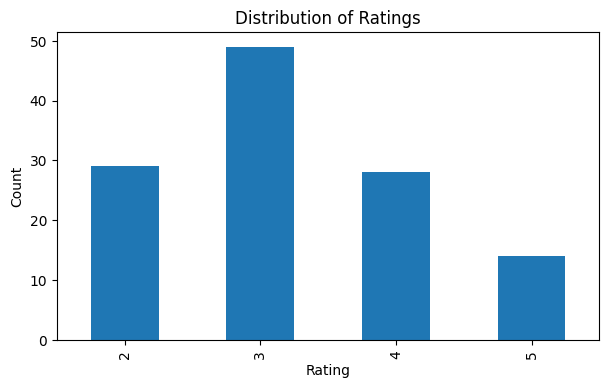

In [3]:
display(ratings["rating"].value_counts().sort_index())

plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

**Interpretation:** Ratings are centred around the middle: 3 is the most common rating (49 of 120, ~41%), followed by 2 (29), 4 (28) and 5 (14), with no 1-star ratings at all. High ratings (4–5) make up only ~35% of the data, so neither high nor low ratings dominate. This matters for evaluation: because only about one in three interactions counts as "relevant" (rating ≥ 4), there will be few relevant items per user to find, which makes Top-N metrics sparse and noisy, and the narrow 2–5 range means rating-prediction errors can look large relative to the spread of the data.

## Step 4 – Create a Train/Test Split

In [4]:
ratings = ratings.sort_values(["user_id", "timestamp"])
test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


**Result:** 108 training interactions (9 per user) and 12 test interactions (1 per user, each user's most recent rating).

Holding out each user's *latest* interaction mimics real use (predict what they will rate next from their past), keeps a training history for every user, and avoids leakage: the model never sees the rating it is evaluated on. The trade-off is that the test set is very small (12 rows), so every metric below is high-variance.

## Step 5 – Build a Popularity Baseline

In [5]:
global_mean = train["rating"].mean()

movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

display(movie_stats.sort_values(
    ["mean_rating", "rating_count"],
    ascending=[False, False]
).head(10))

movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()

baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


**Note:** The "popularity" baseline here ranks movies by *mean rating* first and uses the rating count only as a tie-breaker, so it is really a "highest-rated" baseline. Some top-ranked movies rest on very few ratings (e.g. *Galaxy Mission* n=3, *The Promise* n=2), so their means are unreliable. For rating prediction, a movie with no training rating would fall back to the global training mean (3.22), but every test movie has at least one training rating here.

## Step 6 – Evaluate the Baseline with MAE and RMSE

In [6]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


**Interpretation:** The baseline's MAE of **1.086** means it is wrong by about 1.09 rating points on average, which is large on a scale where ratings mostly sit between 2 and 5. The biggest misses are users 12 and 6 (actual 5, predicted ~3.0 and ~3.1) and user 9 (actual 2, predicted 3.57). A movie-mean baseline gives everyone the same prediction for a given movie, so it cannot capture individual taste.

## Step 7 – Build Item Features for Content-Based Filtering

In [7]:
genre_features = movies["genres"].str.get_dummies(sep="|")

content_items = pd.concat(
    [movies[["movie_id", "title"]], genre_features],
    axis=1
)

genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]

display(content_items.head())

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


## Step 8 – Build a User Preference Profile

In [8]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)

display(pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False))

# Supporting evidence for the student task: User 1's training history
display(train[train["user_id"] == 1].merge(movies, on="movie_id")
        .sort_values("rating", ascending=False)[["title", "genres", "rating"]])

Drama        1.666667
Sci-Fi       1.000000
Comedy       0.888889
Romance      0.666667
Action       0.555556
Family       0.555556
Crime        0.333333
Mystery      0.333333
Adventure    0.222222
dtype: float64

,title,genres,rating
2,Galaxy Mission,Action|Sci-Fi,5
6,Digital Dreams,Sci-Fi|Drama,4
0,Love in Nairobi,Romance|Drama,3
3,Wedding Weekend,Romance|Comedy,3
1,Hidden Truth,Drama|Mystery,3
4,City Detectives,Crime|Drama,3
8,Family Weekend,Comedy|Family,3
5,Home Again,Family|Drama,2
7,Weekend Escape,Comedy|Adventure,2


**Student task – User 1:** The two strongest genre weights are **Drama (1.67)** and **Sci-Fi (1.00)**.

- **Sci-Fi agrees with User 1's favourites:** their two highest ratings are *Galaxy Mission* (5, Action|Sci-Fi) and *Digital Dreams* (4, Sci-Fi|Drama).
- **Drama only partly agrees:** it ranks first mainly because 5 of User 1's 9 training movies are Dramas, and most of those were rated only 2–3 (e.g. *Love in Nairobi* 3, *Hidden Truth* 3, *Home Again* 2). The profile is a rating-weighted *mean* over all rated movies, so genre **frequency** inflates the score, not just genre **liking**.
- **Action is under-weighted (0.56)** even though it belongs to their single 5-star movie.

So the profile is directionally sensible but over-rewards genres the user watches often, which is a known weakness of this simple profile (it does not centre ratings on the user's average).

## Step 9 – Content-Based Rating Prediction

In [9]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


## Step 10 – Build Item-Based Collaborative Filtering

In [10]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

item_similarity.iloc[:5, :5]

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


## Step 11 – Item-Based Rating Prediction

In [11]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    weighted_sum = 0.0
    similarity_sum = 0.0

    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim

    if similarity_sum == 0:
        return global_mean

    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

CF MAE: 0.924
CF RMSE: 1.07


## Step 12 – Compare Rating Prediction Metrics

In [12]:
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


### Answers
6. **Lowest MAE:** Item-Based CF (0.924), then Popularity Baseline (1.086), then Content-Based (1.094).
7. **Lowest RMSE:** Item-Based CF (1.070), then Popularity Baseline (1.201), then Content-Based (1.381).
8. **Does either advanced model clearly beat the baseline?** Only CF beats it, and modestly (MAE −0.16, about 15% lower; RMSE −0.13). The content-based model does **not** beat the baseline: its MAE is essentially the same (1.094 vs 1.086) and its RMSE is clearly worse. Even CF's gain comes from only 12 test ratings, so it is suggestive rather than conclusive.
9. **Why not declare a best model from one metric?** Metrics capture different things. MAE and RMSE disagree about the content model (MAE ≈ baseline, RMSE much worse), meaning it makes a few very large errors that RMSE punishes. And rating-error metrics say nothing about whether the *top of a ranked list* is useful: as Step 15 shows, CF has the best error scores but the worst ranking scores.

## Step 13 – Move from Rating Prediction to Ranking Evaluation

In [13]:
test["relevant"] = test["rating"] >= 4
test[["user_id", "movie_id", "rating", "relevant"]].head()

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False


In [14]:
# How many users actually have a relevant held-out item?
print("Users with a relevant test item:", int(test["relevant"].sum()), "of", len(test))
test[["user_id", "movie_id", "rating", "relevant"]]

Users with a relevant test item: 5 of 12


,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False
59,6,2,5,True
69,7,3,2,False
79,8,12,2,False
89,9,16,2,False
99,10,19,3,False


## Step 14 – Build Top-N Recommendation Functions

In [15]:
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
    )
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

print("Popularity:", recommend_popularity(1))
print("Content:", recommend_content(1))
print("Collaborative:", recommend_cf(1))

Popularity: [6, 18, 16]
Content: [16, 6, 18]
Collaborative: [12, 11, 18]


In [16]:
# Titles for readability
title_map = movies.set_index("movie_id")["title"].to_dict()
for name, fn in [("Popularity", recommend_popularity), ("Content", recommend_content), ("Collaborative", recommend_cf)]:
    print(f"{name:14s}", [title_map[m] for m in fn(1)])

Popularity     ['Broken Hearts', 'The Promise', 'Campus Life']


Content        ['Campus Life', 'Broken Hearts', 'The Promise']
Collaborative  ['The Last Case', 'Laugh Out Loud', 'The Promise']


**Discussion:** For User 1:
- **Popularity** gives *Broken Hearts, The Promise, Campus Life* (the same list every user with these movies unseen would get).
- **Content-based** gives *Campus Life, Broken Hearts, The Promise*: the **same three movies in a different order**. User 1's profile is dominated by Drama, and those are all Drama titles that also happen to be highly rated, so content and popularity converge.
- **Collaborative** gives *The Last Case, Laugh Out Loud, The Promise*, the **most different, and so the most personalised**, list, drawing on co-rating patterns rather than genre or global averages. (It is also the least obviously sensible: its scores rest on few similar items, and *Laugh Out Loud* has the lowest average rating in the catalogue, so personalised does not automatically mean good.)

**Easiest to explain:** Popularity ("the highest-rated movies you haven't seen"), followed by content-based ("matches the genres you rate highly"). Item-CF is hardest to justify to a user ("people who rated X like you also rated Y").

## Step 15 – Precision@K, Recall@K, and NDCG@K

In [17]:
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)

    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3):
    rows = []
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()

        if not relevant:
            continue

        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)

        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })

    result = pd.DataFrame(rows)
    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])

ranking_results

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


In [18]:
# Which held-out relevant items did each model actually hit?
rel_users = test.loc[test["relevant"], ["user_id", "movie_id"]]
for name, fn in [("Popularity", recommend_popularity), ("Content", recommend_content), ("CF", recommend_cf)]:
    hits = [(int(u), title_map[m]) for u, m in rel_users.itertuples(index=False) if m in fn(u, TOP_K)]
    print(f"{name:10s} hits:", hits if hits else "none")

Popularity hits: [(11, 'City Detectives')]


Content    hits:

 [(6, 'Love in Nairobi')]
CF         hits: none


**Interpretation:**
- Only **5 of 12 users** (1, 2, 6, 11, 12) have a relevant held-out item (rating ≥ 4), and each has exactly **one** test item, so the maximum possible Precision@3 is 1/3 ≈ 0.33. Read the 0.067 values against that ceiling, not against 1.0.
- Popularity and Content-Based each find **one** relevant item (popularity: *City Detectives* for user 11 at rank 3; content: *Love in Nairobi* for user 6 at rank 1). They tie on Precision@3 (0.067) and Recall@3 (0.20), but Content has higher NDCG@3 (0.20 vs 0.10) because its hit was ranked first.
- **Item-Based CF finds none (0.0 on all three)**, even though it had the best MAE/RMSE. This illustrates the lab's key lesson: good rating prediction does not guarantee a good Top-N list.
- Differences here come down to **one user**, so they are not statistically meaningful.

## Step 16 – Catalogue Coverage

In [19]:
def catalogue_coverage(recommender, k=3):
    recommended = set()
    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
    ]
})

coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


## Step 17 – Novelty

In [20]:
pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)

def average_novelty(recommender, k=3):
    values = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ]
})

novelty_results

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


## Step 18 – Diversity

In [21]:
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)

def list_diversity(movie_ids):
    sims = []
    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(
                genre_similarity.loc[movie_ids[i], movie_ids[j]]
            )
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=3):
    return np.mean([
        list_diversity(recommender(user_id, k))
        for user_id in train["user_id"].unique()
    ])

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity),
        average_diversity(recommend_content),
        average_diversity(recommend_cf)
    ]
})

diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


## Step 19 – Build a Unified Evaluation Table

In [22]:
summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)

summary.round(3)

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.086,1.201,0.067,0.2,0.1,0.35,1.689,0.736
1,Content-Based,1.094,1.381,0.067,0.2,0.2,0.70,1.344,0.542
2,Item-Based CF,0.924,1.070,0.000,0.0,0.0,0.85,1.695,0.780


**Reading the unified table:**
- **Rating accuracy:** Item-CF is best (lowest MAE and RMSE); Content-Based is worst on RMSE.
- **Ranking quality:** Content-Based is best (NDCG@3 = 0.20), Popularity is next, and Item-CF is worst (0 hits). The model ordering flips between accuracy and ranking.
- **Coverage:** Popularity covers only 35% of the catalogue (7 of 20 movies); Content covers 70% and Item-CF 85%.
- **Novelty:** Item-CF (1.695) ≈ Popularity (1.689) > Content (1.344). Popularity's novelty is not low because this baseline sorts by *mean rating*, not by interaction count, so its top picks (e.g. *Galaxy Mission*, *The Promise*) are actually rarely rated. Content is lowest because Drama-heavy profiles push already-common titles.
- **Diversity:** Item-CF (0.780) > Popularity (0.736) > Content (0.542). Content lists are genre-homogeneous, a "filter bubble" effect.

## Step 20 – Interpret Evaluation Trade-Offs

The results in this lab illustrate each trade-off listed in the lab sheet:

- **Better RMSE but weaker ranking:** Item-CF has the best MAE/RMSE but the worst ranking (0 hits, NDCG@3 = 0).
- **High precision but low coverage:** Popularity matches Content on Precision@3 but exposes only 35% of the catalogue, versus 70% for Content.
- **Accurate but recommends already-popular items:** The popularity baseline gives everyone almost the same list (8 distinct lists for 12 users, produced only by filtering out seen movies).
- **Diverse and novel but slightly less precise:** Item-CF is the most diverse (0.78), the most novel (1.69) and has the highest coverage (0.85), but registers no ranking hits.
- **Easy to explain but less accurate:** Popularity and Content are the easiest to explain, but Content has the worst RMSE and the lowest diversity.

There is no model that wins everything. The right choice depends on the business objective.

## Step 21 – Final Business Scenario

**Scenario:** *"Users should discover relevant movies, but the same popular titles should not dominate every list."*

10. **Model chosen: Item-Based Collaborative Filtering.** Popularity is ruled out: its coverage is only 35% and it gives near-identical lists to everyone, which is exactly the "same titles dominate" problem. Between the two personalised models, Item-CF is stronger on the anti-dominance goals.
11. **Metrics that influenced the choice most:** (a) **Catalogue coverage** (CF 0.85 vs Content 0.70 vs Popularity 0.35), (b) **Novelty** (CF 1.695 vs Content 1.344), and (c) **MAE/RMSE** as the best available signal of relevance (CF is the most accurate). Diversity (CF 0.78) points the same way.
12. **Trade-off accepted:** CF registered **zero Top-3 hits** (Precision/Recall/NDCG@3 = 0), while Content-Based achieved the best NDCG@3 (0.20). I am trading unproven short-list relevance for much broader, more novel, more diverse discovery. If management weighted raw relevance above discovery, Content-Based (or a hybrid of the two) would be the alternative. In a real deployment I would also expect a hybrid to be the safest choice.
13. **Limitation of this evaluation:** The data is tiny (12 users, 20 movies) and each user has only one held-out item, so just 5 users have a relevant test item. The CF-vs-Content ranking difference is literally one user's hit, so these ranking results cannot be treated as reliable. Other limitations: genre-only item features; a threshold of rating ≥ 4 that is arbitrary; and a single temporal split with no repeated runs or confidence intervals.

## Step 22 – Extension Challenge (Option C – Compare Personalization)

In [23]:
def show_recs(user_id):
    print(f"--- User {user_id} ---")
    seen = train.loc[train['user_id'] == user_id].merge(movies, on='movie_id').sort_values('rating', ascending=False)
    print("Top-rated in training:", list(seen.head(3)['title']), "| genres:", list(seen.head(3)['genres']))
    for name, fn in [("Popularity", recommend_popularity), ("Content", recommend_content), ("Item-CF", recommend_cf)]:
        print(f"  {name:11s}", [title_map[m] for m in fn(user_id, TOP_K)])

for u in [1, 6]:
    show_recs(u)

# Quantify personalisation: how many distinct Top-3 lists does each model produce across all users?
for name, fn in [("Popularity", recommend_popularity), ("Content", recommend_content), ("Item-CF", recommend_cf)]:
    lists = {tuple(fn(u, TOP_K)) for u in train['user_id'].unique()}
    print(f"{name:11s} distinct Top-3 lists across {train['user_id'].nunique()} users: {len(lists)}")

--- User 1 ---
Top-rated in training: ['Galaxy Mission', 'Digital Dreams', 'Love in Nairobi'] | genres: ['Action|Sci-Fi', 'Sci-Fi|Drama', 'Romance|Drama']
  Popularity  ['Broken Hearts', 'The Promise', 'Campus Life']
  Content     ['Campus Life', 'Broken Hearts', 'The Promise']
  Item-CF     ['The Last Case', 'Laugh Out Loud', 'The Promise']
--- User 6 ---
Top-rated in training: ['Broken Hearts', 'Hidden Truth', 'Campus Life'] | genres: ['Drama|Romance', 'Drama|Mystery', 'Comedy|Drama']
  Popularity  ['Galaxy Mission', 'The Promise', 'Family Weekend']
  Content     ['Love in Nairobi', 'The Promise', 'Digital Dreams']
  Item-CF     ['The Promise', 'Galaxy Mission', 'The Last Case']
Popularity  distinct Top-3 lists across 12 users: 8
Content     distinct Top-3 lists across 12 users: 12


Item-CF     distinct Top-3 lists across 12 users: 12


**Option C – Compare personalisation: findings**

- **Popularity does not genuinely personalise.** It uses one global ordering and only personalises by removing movies the user has already rated. Across the 12 users it produced just **8 distinct Top-3 lists**, e.g. *Galaxy Mission, The Promise, Family Weekend* for User 6 and *Broken Hearts, The Promise, Campus Life* for User 1.
- **Content-Based genuinely personalises through genre profiles** (12 distinct lists for 12 users). For User 6, whose top rated movies are Drama/Romance, it recommends *Love in Nairobi*, *The Promise* and *Digital Dreams*. For User 1 it mostly mirrors popularity because their Drama-heavy profile points to the same highly rated Drama titles.
- **Item-CF genuinely personalises through co-rating patterns** (12 distinct lists). It gave *The Last Case, Laugh Out Loud, The Promise* to User 1 and *The Promise, Galaxy Mission, The Last Case* to User 6.
- *The Promise* appears in the lists of both users under all three models, so it is a "safe" item that everything agrees on.

**Conclusion:** Content-Based and Item-CF personalise genuinely; the popularity baseline only filters already-seen items. Different lists are not, however, evidence of *better* lists, as the Step 15 ranking results show.

## Final Reproducibility Note
Kernel restarted and all cells run top-to-bottom before submission.